In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!unzip -q "/content/drive/MyDrive/plant_dataset.zip" -d /content/
!ls /content/plant_dataset

test  train  val


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

DATA = "/content/plant_dataset"
IMG_SIZE = (224, 224)
BATCH = 32

train_ds = keras.utils.image_dataset_from_directory(
    f"{DATA}/train", image_size=IMG_SIZE, batch_size=BATCH, seed=42)
val_ds = keras.utils.image_dataset_from_directory(
    f"{DATA}/val", image_size=IMG_SIZE, batch_size=BATCH)
test_ds = keras.utils.image_dataset_from_directory(
    f"{DATA}/test", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
print(class_names)

Found 3920 files belonging to 14 classes.
Found 490 files belonging to 14 classes.
Found 490 files belonging to 14 classes.
['Apple', 'Blueberry', 'Cherry', 'Corn', 'Grape', 'Orange', 'Peach', 'Pepper', 'Potato', 'Raspberry', 'Soybean', 'Squash', 'Strawberry', 'Tomato']


In [ ]:
data_aug = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

base = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = data_aug(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
history = model.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 19s 77ms/step - accuracy: 0.6898 - loss: 1.0798 - val_accuracy: 0.9204 - val_loss: 0.3910
Epoch 2/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step - accuracy: 0.9212 - loss: 0.3340 - val_accuracy: 0.9449 - val_loss: 0.2522
Epoch 3/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - accuracy: 0.9441 - loss: 0.2376 - val_accuracy: 0.9612 - val_loss: 0.1928
Epoch 4/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 8s 67ms/step - accuracy: 0.9538 - loss: 0.1829 - val_accuracy: 0.9612 - val_loss: 0.1620
Epoch 5/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 8s 68ms/step - accuracy: 0.9594 - loss: 0.1590 - val_accuracy: 0.9531 - val_loss: 0.1535
Epoch 6/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.9658 - loss: 0.1361 - val_accuracy: 0.9633 - val_loss: 0.1411
Epoch 7/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - accuracy: 0.9740 - loss: 0.1155 - val_accuracy: 0.9633 - val_loss: 0.1248
Epoch 8/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - accuracy: 0.9732 - loss: 0.1085 - val_ac

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.9531 - loss: 0.1409
Test accuracy: 0.9530612230300903
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 262ms/step


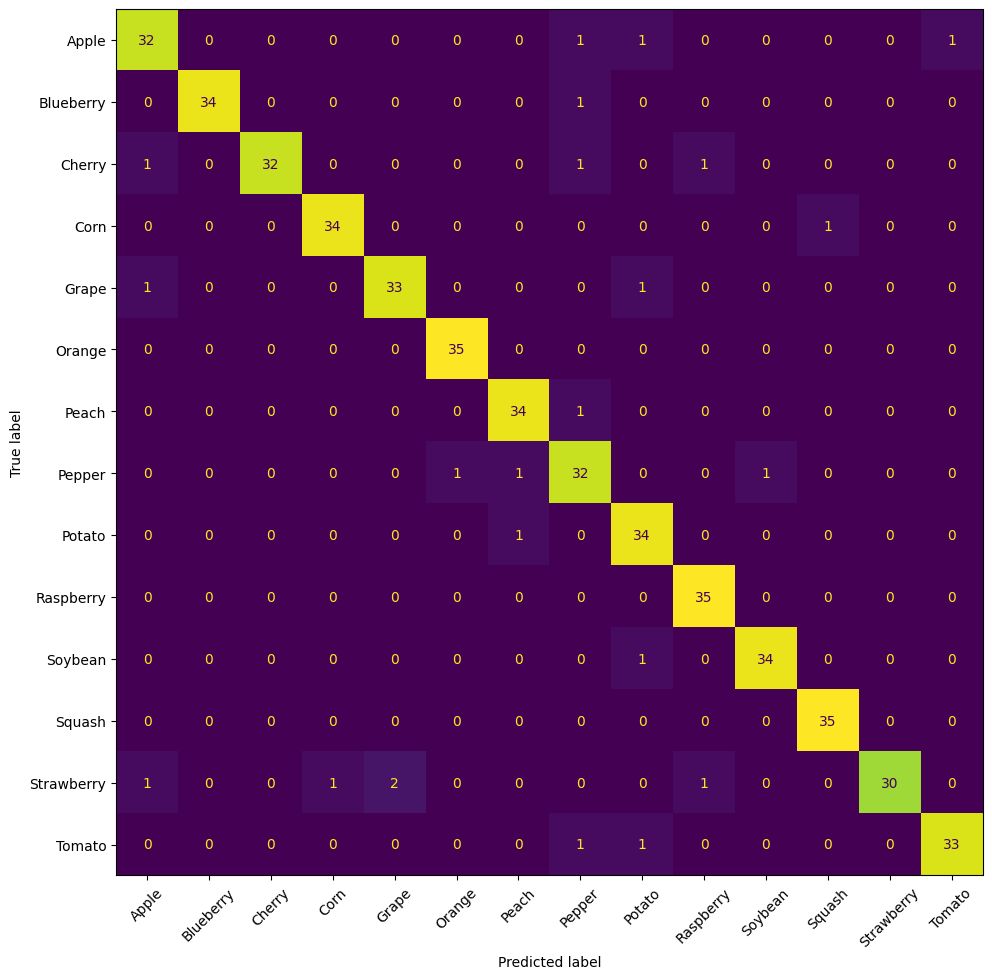

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

loss, acc = model.evaluate(test_ds)
print("Test accuracy:", acc)

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

In [ ]:
model.save("/content/drive/MyDrive/plant_model.keras")
with open("/content/drive/MyDrive/class_names.txt", "w") as f:
    f.write("\n".join(class_names))
!cp confusion_matrix.png /content/drive/MyDrive/